# PTM3D notebook 02: Europa through a Jupiter eclipse

One Europa day over the whole moon. Europa rotates synchronously, so its orbital period around
Jupiter, 3.55 Earth days, is also its day. Once per orbit it passes through Jupiter's shadow, and
the direct sunlight drops to zero over the whole moon for about 2.7 hours. The `start_time` of
this run places one eclipse inside the output window.

The notebook follows [notebook 01](01_moon_diurnal.ipynb), which introduces the results reader,
the output format and the color scales used here. Beyond the eclipse it shows the effect of the
spin-up length, the effect of Europa's observed albedo map, and what happens to an albedo set by
hand when that map is loaded.

**Cost:** about ten minutes on four cores for nine runs on a 5,120-face sphere, under 1 GB of
memory. Radiation exchange is off, because no face of a convex sphere sees another.

**Needs:** the `ptm` package, a built `ptm_thermal_sim`, and the Europa SPICE kernels. Unlike the
Moon's, these include the 1.1 GB ephemeris of the Galilean satellites, `jup365.bsp`, because
Europa's position relative to Jupiter produces the eclipse.

In [1]:
from ptm import paths, run as engine

# Resolution of the figures stored in the notebook.
%config InlineBackend.print_figure_kwargs = {"bbox_inches": "tight", "dpi": 100}

CONFIG = "examples/quickstart_europa_diurnal.yaml"
pre = paths.preflight([CONFIG, "data/kernels/europa.tm",
                       "data/kernels/lsk/naif0012.tls",
                       "data/kernels/spk/jup365.bsp"], engine="ptm_thermal_sim")
print(pre)
pre.raise_if_missing()

found    <repo>/build/bin/ptm_thermal_sim
found    examples/quickstart_europa_diurnal.yaml
found    data/kernels/europa.tm
found    data/kernels/lsk/naif0012.tls
found    data/kernels/spk/jup365.bsp

Repo root: <repo>
Engine:    <repo>/build/bin/ptm_thermal_sim


<Report 5/5 found>

## 1. Running the model

The run takes under a minute on four cores.

In [2]:
europa = engine.run_engine(pre.root / CONFIG, echo=True).results()

Running: <repo>/build/bin/ptm_thermal_sim --config <repo>/examples/quickstart_europa_diurnal.yaml
(cwd=<repo>)

╔═══════════════════════════════════════════════════════════════╗
║    *      .    *     \   ||    //      * .   .      *         ║
║       .      *     \  \  ||   //    //       .             .  ║
║  *      .       \   \  \  ☀  //    //      .      *           ║
║     .         *  \   ...-'''''-...//    *         .           ║
║           _ ... .-'''''   PTM3D     ``''-.....,__      .      ║
║   __,.-''    Planetary Thermophysical Model 3D     `'-..., _  ║
║  ═══════════════════════════════════════════════════════════  ║
║      Coupled Thermal-Illumination for Planetary Bodies        ║
╚═══════════════════════════════════════════════════════════════╝
Successfully loaded configuration from: <repo>/examples/quickstart_europa_diurnal.yaml
✓ Configuration loaded from: <repo>/examples/quickstart_europa_diurnal.yaml
[gpu] Thermal dispatch target: 1.5 s (default)
Hapke albedo gate:

Loaded SPICE meta-kernel: <repo>/data/kernels/europa.tm
========== Thermal Equilibration Configuration ==========
Body: Europa
Synodic day (solar day): 3.55 Earth days
Equilibration (configured): 20.00 day/night cycles  (thermal.equilibration_orbits)
Equilibration (integrated): 20.00 day/night cycles = 1 pass(es) x 20.00-cycle forcing block  [default]
Seed surface anchor: lumped  (cycle-mean lumped-substrate anchor; the run's per-face census and its QUADRATURE are printed by the solver)
Spin-up seed: physical  (shared per-face conductive steady profile, identical on every solver path)
Equilibration (analytic seed, CPU paths only): 0 day/night cycles  (OFF -- spin-up is the configured equilibration under the REAL forcing)
Total equilibration period: 71.00 Earth days
Output window (for export): 3.55 Earth days
Requested integration (stats): 3.55 days with offset 0.00 days
Post-equilibration simulated span: 3.55 Earth days
Total simulation time: 74.55 Earth days
Time step calculation:
Req

[illumination] primary-disk body cull: inactive (closed mesh: Embree self-occludes)
Calculating illumination:  [>                                                 ] 0% | elapsed 0s


Calculating illumination:  [============>                                     ] 25% | elapsed 1s, ETA 3s


Calculating illumination:  [=========================>                        ] 50% | elapsed 2s, ETA 2s


Calculating illumination:  [=====================================>            ] 75% | elapsed 3s, ETA 1s


... (8 outputs left out)

Progress 109/192


Progress 163/192
Progress 192/192
Export complete: 192/192
Binary export completed successfully!
Data successfully written in binary format to: output/quickstart_europa_diurnal
[Statistics] Exporting statistics over integration window...
[exportStatisticsBinary] Computing and exporting statistics...
Face count: 5120
Time steps: 192
Computing illumination statistics...
Computing direct solar statistics...
Computing primary reflected statistics...
Computing primary IR statistics...


Computing temperature statistics...
[exportStatisticsBinary] Statistics export completed successfully!
[Statistics] Exported to output/quickstart_europa_diurnal/statistics
[albedo] effective surface albedo (flux-weighted over the DIRECT beam, the value the BC absorbed with): global A_eff = 0.56723 over 5116/5120 ever-lit faces; per-face -> output/quickstart_europa_diurnal/statistics/effective_albedo.bin (uint32 n + float32[5120], NaN where never lit).
Reduced over the INTEGRATION window, abs steps [3840,4032) -- the same window as every other statistics/*.bin, so a closure audit may divide the two directly.
[kirchhoff] absorb == emit == scatter: eps = 0.9 (IR albedo 0.1) at cpu_array=0.90000000000000002, emit=0.9, radiosity=n/a (radiation off)
[cadence-advisor] post-run: estimated upper bound on the fractional overstatement of the cold-trap area = (area of all faces lit in exactly one output frame, 0% of the mesh) / (area with frame-sampled T_max below the threshold): 0% at 110 K (cold


--- 466 output lines; 12.2 s wall; exit code 0 ---


## 2. Maximum temperature on the globe

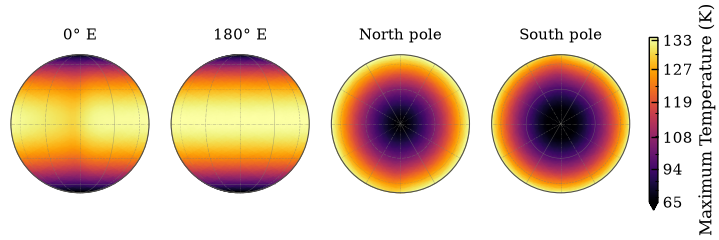

In [3]:
fig = europa.plot_globes("temperature", "max")

The field varies with latitude only, as it must for a smooth sphere of uniform ice. The peak
temperature is only about 135 K, because Europa is 5.2 AU from the Sun, where the solar flux is
3.7% of that at Earth, and its ice is bright.

Two effects disturb these bands later. Section 7 shows a narrow notch at the sub-Jupiter
meridian, left by the eclipse, and confirms that it is not an artifact of the spin-up. Section 8 replaces the uniform albedo with the observed
map.

## 3. The configuration

[`examples/quickstart_europa_diurnal.yaml`](../../../examples/quickstart_europa_diurnal.yaml)
is the Europa counterpart of the Moon configuration of notebook 01, a small mesh without
radiation exchange. `examples/europa_high_res.yaml` describes a much larger simulation, on a
level-7 mesh with the GPU, and is not intended for a laptop.

In [4]:
print((pre.root / CONFIG).read_text())

# PTM3D quickstart: Europa diurnal (one orbit) run on a small icosphere (ico4, 5120 faces).
#
# Laptop-friendly (CPU-only, radiation off, < 1 GB RAM, seconds of wall time). All
# paths are relative — run FROM THE REPOSITORY ROOT after fetching SPICE kernels:
#
#     python3 scripts/fetch_kernels.py --bodies europa   # once, ~1.1 GB from NAIF
#     ./build/bin/ptm_thermal_sim --config examples/quickstart_europa_diurnal.yaml
#
# Europa is tidally locked, so one "diurnal cycle" IS one orbit around Jupiter
# (3.55 Earth days) — unlike the Moon, whose 29.53-day synodic day is much
# longer than its (irrelevant, for surface heating) sidereal rotation.
#
# start_time is pinned to 2025-01-01T00:00:00 deliberately: at this epoch a
# full Jupiter eclipse (Europa passing through Jupiter's shadow) falls at
# ~18:06-20:33 UTC on day 1, i.e. inside this run's single-orbit output
# window. Direct solar flux drops to exactly zero, body-wide, for ~2.7 h
# (6 of 192 output steps) — Europa's signature ph

These are the settings particular to Europa.

- `body: Europa` selects the built-in ephemeris, the radius (1,560.8 km), the properties of the
  icy regolith (Bond albedo 0.5, emissivity 0.9, thermal inertia near 60 SI, internal heat flow
  $Q_b = 0.03$ W/m²), and Jupiter as the primary body through the Galilean ephemeris in
  `europa.tm`. No configuration key names Jupiter.
- Europa receives direct sunlight, sunlight reflected by Jupiter, and Jupiter's thermal
  emission. `illumination.include_primary_reflection` controls only the reflected sunlight.
  Jupiter's thermal emission is always included, so setting the key to `false` removes the
  reflected light and keeps Jupiter's infrared heating (exercise 2).
- `equilibration_orbits: 20.0` integrates twenty orbits of spin-up before the output window.
  Europa's icy regolith has a thin diurnal skin depth, about 5 cm, so the surface settles within
  an orbit or two, while the layers below take much longer (section 7).
- `mesh.resolution: 4` gives 5,120 faces, one level finer than the Moon quickstart, because
  Europa is smaller.

The output directory has the same layout as in notebook 01. `body_positions.csv` gives two
vectors in each row, `sun_*` and `primary_*`, both in km from Europa's center.

In [5]:
import numpy as np

for moment in ("max", "avg", "min"):
    v = europa.stat("temperature", moment)
    print(f"temperature_{moment:3s}   min {v.min():6.2f}   median {np.median(v):6.2f}"
          f"   max {v.max():6.2f} K")

tmax, tmin = europa.stat("temperature", "max"), europa.stat("temperature", "min")
cold = int(np.sum(tmax < 40.0))
print(f"\n{cold} of {tmax.size} faces never exceed 40 K even at their warmest: "
      "near-polar faces that this coarse mesh never lights.")

temperature_max   min  27.89   median 125.67   max 133.52 K
temperature_avg   min  27.89   median 102.75   max 108.03 K
temperature_min   min  27.88   median  89.55   max  92.78 K

6 of 5120 faces never exceed 40 K even at their warmest: near-polar faces that this coarse mesh never lights.


The faces that are never lit test the floor of the model. A face that receives no flux at any time
must reach the temperature at which the internal heat flow balances thermal emission,
$T = (Q_b/\varepsilon\sigma)^{1/4}$, which is 27.7 K for $Q_b = 0.03$ W/m² and
$\varepsilon = 0.9$. The coldest faces are within 0.2 K of it.

## 4. Finding the eclipse

An eclipse is a global event (the entire day side loses the Sun at once,
not a terminator sweeping across), so the clearest signature is the direct solar
flux summed over every face. `stack()` reads all output steps of a per-step
field into one `(n_steps, n_faces)` array.

In [6]:
direct = europa.stack("direct_solar")
eclipse = np.where(direct.sum(axis=1) < 1e-6)[0]
if eclipse.size == 0:
    raise RuntimeError("no eclipse in this output window; the eclipse analysis "
                       "below depends on the config's start_time capturing one")

utc = europa.times().utc
cadence_h = float(np.median(np.diff(europa.elapsed_hours)))
print(f"{eclipse.size} fully dark output steps at a {60 * cadence_h:.0f} min cadence "
      f"= at least {eclipse.size * cadence_h:.1f} h of total shadow")
print(f"{utc[eclipse[0]]} -> {utc[eclipse[-1]]}  (the steps on either side are already "
      "partway into ingress and egress, so the true eclipse is a little longer still)")

6 fully dark output steps at a 27 min cadence = at least 2.7 h of total shadow
2025-01-01T18:11:37.500 -> 2025-01-01T20:24:45.000  (the steps on either side are already partway into ingress and egress, so the true eclipse is a little longer still)


### The eclipse at one face

The next cell takes the face with the highest direct solar flux in the step immediately before
ingress, which is near local noon at that moment and so shows the largest effect, and plots its
whole diurnal curve with the eclipse window shaded.

cooled 24.1 K inside the shadow


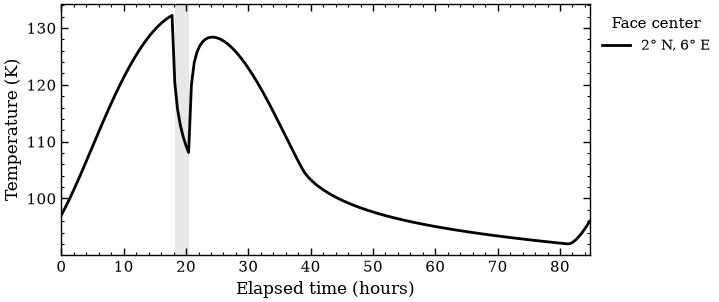

In [7]:
from ptm import plots

plt = plots.styled()                 # the project's figure style
face = int(np.argmax(direct[eclipse[0] - 1]))
t_hr, curve = europa.series("temperature", face=face)
cooling = curve[:eclipse[0]].max() - curve[eclipse[0]:eclipse[-1] + 1].min()

ax = europa.plot_diurnal(face=face).axes[0]
ax.axvspan(t_hr[eclipse[0]], t_hr[eclipse[-1]], **plots.SHADES["eclipse"])   # fully dark steps
print(f"cooled {cooling:.1f} K inside the shadow")

The temperature does not follow the flux to zero. It falls about 24 K in the 2.7 hours of the
eclipse, and when sunlight returns it recovers only partly, so the peak after the eclipse is
lower than the one before, because the shadow interrupted the warming toward local noon.

Both effects come from the thin thermal skin. Europa's porous-ice regolith
($k_s = 0.0096$ W/m/K, $\rho_s = 500$ kg/m³, $c_p \approx 750$ J/kg/K) has a diurnal skin
depth $\delta = \sqrt{\kappa P/\pi} \approx 5$ cm for a 3.55-day period. A thin skin responds
quickly, which is why the surface cools visibly within three hours, but it also stores little
heat.

## 5. Day/night contrast, and the comparison with the Moon

Moon (tutorial 01)   median face:  369.7 -  92.6 K, swing  277.1 K, Tmin/Tmax 0.25
Europa (this run)    median face:  125.7 -  89.5 K, swing   36.1 K, Tmin/Tmax 0.71


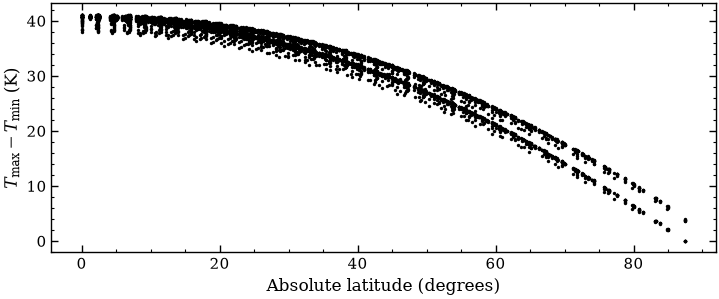

In [8]:
contrast = tmax - tmin
fig, ax = plt.subplots(figsize=(plots.DOUBLE_W, 3.0), layout="constrained")
ax.scatter(np.abs(europa.lat), contrast, s=6, linewidths=0, color=plots.BLACK)
ax.set_xlabel("Absolute latitude (degrees)")
ax.set_ylabel(r"$T_\mathrm{max} - T_\mathrm{min}$ (K)")

MOON_TMAX, MOON_TMIN = 369.7, 92.6            # medians from tutorial 01
for name, hi, lo in (("Moon (tutorial 01)", MOON_TMAX, MOON_TMIN),
                     ("Europa (this run)", float(np.median(tmax)), float(np.median(tmin)))):
    print(f"{name:20s} median face: {hi:6.1f} - {lo:5.1f} K, "
          f"swing {hi - lo:6.1f} K, Tmin/Tmax {lo / hi:.2f}")

Between noon and dawn the Moon's median face cools to a quarter of its peak temperature, and
Europa's only to seven tenths. The material is not the reason, because the two thermal inertias
are similar. The length of the night is. Europa's night lasts 1.8 Earth days and the Moon's 14.8,
so Europa has about eight times less time to radiate away the heat stored during the day. The
mechanism is the same as the Moon's nighttime plateau, and its larger effect here comes from the
orbital period, not the regolith.

## 6. The eclipse as a global event

The same instant seen from the Sun's direction and from the night side, plus the
mid-eclipse step from the same viewpoint. One row of `globe_grid` can hold
different fields in different columns, which is how a row compares output steps.

the day side cooled by a median of 13.2 K between the two steps


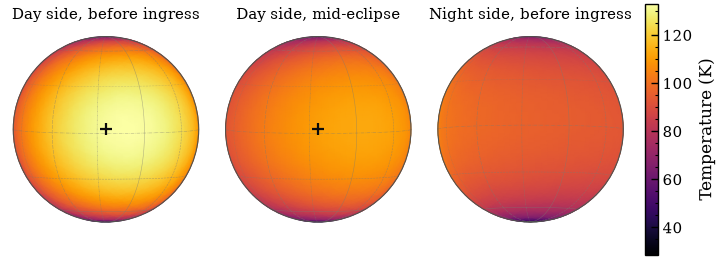

In [9]:
before, dark = int(eclipse[0] - 1), int(eclipse[len(eclipse) // 2])
sub = europa.subsolar_latlon(before)
T_before, T_dark = europa.field("temperature", before), europa.field("temperature", dark)

fig = europa.globe_grid(
    rows=[{"what": [T_before, T_dark, T_before], "label": "Temperature (K)", "mark": sub}],
    views=[(sub[0], sub[1], "Day side, before ingress"),
           (sub[0], sub[1], "Day side, mid-eclipse"),
           (-sub[0], sub[1] + 180, "Night side, before ingress")],
    figsize=(plots.DOUBLE_W, 2.8))
lit = T_before > 100.0
print(f"the day side cooled by a median of {np.median(T_before[lit] - T_dark[lit]):.1f} K "
      f"between the two steps")

The cross marks the sub-solar point. The whole sunlit hemisphere dims together, the signature of a shadow cast by
Jupiter rather than of a terminator moving across the surface. The third panel
is the same instant from the anti-solar direction, and it is barely darker than
the first. Europa's night side is only tens of kelvin below its day side, the
short-night effect quantified in section 5.

## 7. Spin-up length

`thermal.equilibration_orbits` sets how long the model runs before the output window opens. A
spin-up that is too short does not give an obviously wrong result. It gives a plausible one that
still carries structure from the initial condition.

Two effects could put structure in longitude into the map of section 2.

*Physical.* An eclipse happens when Europa is directly behind Jupiter as seen from the Sun, so at
that moment the subsolar point is also the sub-Jupiter point. Europa rotates synchronously, so
the sub-Jupiter point is always the same place on the surface. Every eclipse therefore removes
sunlight at local noon on the same meridian, which should leave a permanent cold notch a few
degrees wide.

*Numerical.* After a short spin-up, the deep layers still carry their initial temperatures when
the output window opens, and they relax during the window. The subsolar longitude moves steadily
through the window, so a slow drift in time becomes a smooth ramp in longitude across the map.

A longer spin-up leaves the notch and would shrink a ramp. The next cell repeats the run with
`--equilibration-orbits 5` and compares the faces around the equator, which should all reach the
same peak.

In [10]:
short = engine.run_engine(pre.root / CONFIG, show=("Simulation completed in",),
                          extra_args=["--equilibration-orbits", "5",
                                      "--output", "output/quickstart_europa_diurnal_eq5"]
                          ).results()

lat, lon = europa.lat, europa.lon
ring = np.isclose(np.abs(lat), np.abs(lat).min(), atol=0.02)
order = np.argsort(lon[ring])
for label, field in (("5 orbits ", short.stat("temperature", "max")), ("20 orbits", tmax)):
    r = field[ring][order]
    print(f"equatorial ring, {label}: Tmax {r.min():.1f}-{r.max():.1f} K "
          f"(spread {r.max() - r.min():.2f} K), coldest at longitude "
          f"{lon[ring][order][np.argmin(r)]:+.0f} deg")

    Simulation completed in 4.337 seconds (4337 ms)
equatorial ring, 5 orbits : Tmax 130.1-133.5 K (spread 3.40 K), coldest at longitude -5 deg
equatorial ring, 20 orbits: Tmax 129.9-133.5 K (spread 3.56 K), coldest at longitude -5 deg


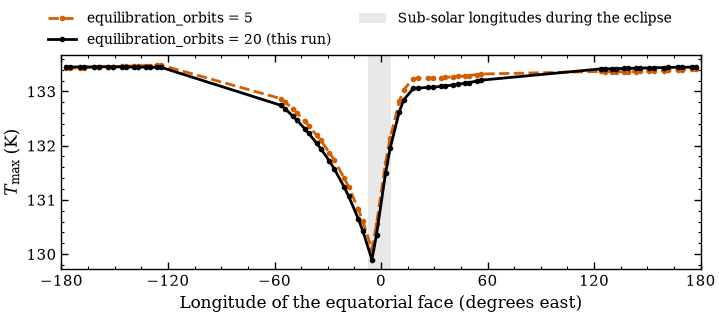

In [11]:
lon_in = europa.subsolar_latlon(int(eclipse[0]) - 1)[1]
lon_out = europa.subsolar_latlon(int(eclipse[-1]) + 1)[1]

fig, ax = plt.subplots(figsize=(plots.DOUBLE_W, 3.2), layout="constrained")
for field, style, label in ((short.stat("temperature", "max"), dict(color=plots.VERMILLION, ls="--"),
                             "equilibration_orbits = 5"),
                            (tmax, dict(color=plots.BLACK, ls="-"),
                             "equilibration_orbits = 20 (this run)")):
    ax.plot(lon[ring][order], field[ring][order], marker="o", ms=3, **style, label=label)
ax.axvspan(lon_out, lon_in, **plots.SHADES["eclipse"],
           label="Sub-solar longitudes during the eclipse")
ax.set_xlabel("Longitude of the equatorial face (degrees east)")
ax.set_ylabel(r"$T_\mathrm{max}$ (K)")
ax.set_xlim(-180, 180)
ax.set_xticks(range(-180, 181, 60))
fig.legend(loc="outside upper center", ncol=2);

Both spin-ups give the same result. The coldest point of the ring is the sub-Jupiter meridian,
about 5° west here, which is the eclipse notch, and the spread changes by less than 0.2 K between
5 and 20 orbits. There is no ramp, because each face's column starts from its own conductive
steady-state profile (`thermal.spinup_seed: physical`), so little of the initial condition
remains.

The surface settles within a few orbits, and the deeper layers take longer. The spin-up estimate
in the log gives the number of orbits needed for 0.1 K. Choose the spin-up for the accuracy the
question needs, and check it as this section does, by lengthening it and comparing.

## 8. Europa's observed albedo map

Everything above used one Bond albedo, 0.5, for the whole moon. Europa is not uniform. The leading
and trailing hemispheres differ, and bright ice plains lie next to dark chaos terrain and lineae.
PTM3D can read a Bond albedo for each face and use it in the absorbed flux instead of the single
value.

The maps are downloaded separately from the repository.

```bash
python3 scripts/fetch_data.py --dataset albedo-maps    # Moon and Europa, levels 3 to 9
```

The model chooses the file that matches the mesh (`mesh.resolution: 4` reads
`Europa_Albedo_res4.bin`). If it finds none, it uses the uniform albedo, and the log reports this.
`examples/quickstart_europa_albedo_map.yaml` differs from the configuration above only in
`illumination.use_albedo_map: true`, so the difference between the two outputs comes from the
map alone.

In [12]:
ALBEDO_MAP = "data/albedo_maps/Europa_Albedo_res4.bin"
albedo_check = paths.preflight([ALBEDO_MAP])
albedo_check.raise_if_missing()
albedo_file = albedo_check.checks[0].path   # resolved through $PTM_DATA_ROOT when it is set

mapped = engine.run_engine(pre.root / "examples/quickstart_europa_albedo_map.yaml",
                           show=("Albedo range", "Simulation completed in")).results()
albedo = europa.albedo_map(albedo_file)
tmax_map = mapped.stat("temperature", "max")
d_tmax = tmax_map - tmax
d_tmin = mapped.stat("temperature", "min") - tmin

    Albedo range: 0.140321 to 0.897313
    Albedo range: 0.140321 to 0.897313
    Simulation completed in 11.431 seconds (11431 ms)


In [13]:
print(f"map Bond albedo {albedo.min():.3f}-{albedo.max():.3f}, mean {albedo.mean():.3f} "
      f"against the uniform 0.500")
print(f"Tmax change: mean {d_tmax.mean():+.2f} K, RMS {d_tmax.std():.2f} K, "
      f"range {d_tmax.min():+.1f} to {d_tmax.max():+.1f} K")
print(f"Tmin change: mean {d_tmin.mean():+.2f} K, RMS {d_tmin.std():.2f} K")
print(f"correlation of the Tmax change with albedo: "
      f"r = {np.corrcoef(albedo, d_tmax)[0, 1]:+.2f}")

map Bond albedo 0.140-0.897, mean 0.549 against the uniform 0.500
Tmax change: mean -4.76 K, RMS 10.16 K, range -44.3 to +24.0 K
Tmin change: mean -2.28 K, RMS 4.58 K
correlation of the Tmax change with albedo: r = -0.99


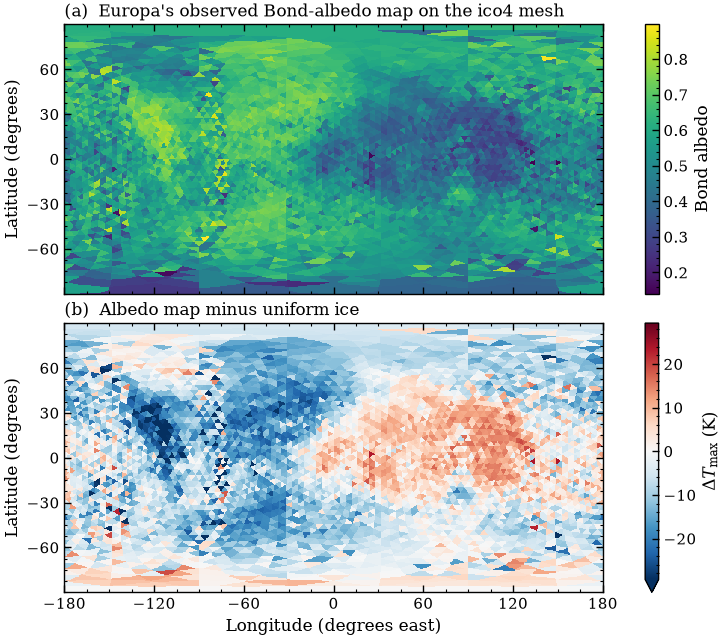

In [14]:
from matplotlib.colors import Normalize

# A half-degree map in which each pixel takes the value of the nearest face.
from scipy.spatial import cKDTree
lon_px, lat_px = np.arange(-179.75, 180.0, 0.5), np.arange(-89.75, 90.0, 0.5)
LON, LAT = np.meshgrid(np.radians(lon_px), np.radians(lat_px))
pixels = np.stack([np.cos(LAT) * np.cos(LON), np.cos(LAT) * np.sin(LON), np.sin(LAT)], axis=-1)
nearest = cKDTree(europa.face_unit_vectors).query(pixels)[1]

fig, axes = plt.subplots(2, 1, figsize=(plots.DOUBLE_W, 6.4), sharex=True, layout="constrained")
for ax, values, cmap, norm, label in (
        (axes[0], albedo, plots.CMAP_SCALAR, Normalize(albedo.min(), albedo.max()), "Bond albedo"),
        (axes[1], d_tmax, plots.CMAP_DIFF, plots.sym_norm(d_tmax), r"$\Delta T_\mathrm{max}$ (K)")):
    art = ax.pcolormesh(lon_px, lat_px, values[nearest], cmap=cmap, norm=norm, shading="nearest")
    plots.colorbar(fig, art, ax, label, values, norm)
    ax.set_aspect("equal")
    ax.set_xticks(range(-180, 181, 60))
    ax.set_yticks(range(-60, 61, 30))          # no -90 label against the -180 below it
    ax.set_ylabel("Latitude (degrees)")
axes[-1].set_xlabel("Longitude (degrees east)")
plots.panel_labels(axes, titles=["Europa's observed Bond-albedo map on the ico4 mesh",
                                 "Albedo map minus uniform ice"])

### Comparison with the radiative-equilibrium law

At radiative equilibrium the absorbed flux carries a factor $(1-A)$ and the
temperature is its fourth root, so replacing albedo $A_0$ by $A$ on the same
face should scale the peak temperature by

$$\frac{T}{T_0} = \left(\frac{1-A}{1-A_0}\right)^{1/4}.$$

This prediction has no free parameters. It is not expected to be exact, because
`incidence_angle_albedo: true` means the absorbed flux uses a
directional-hemispheric albedo built from the Bond albedo rather than the Bond
albedo itself, and thermal inertia keeps the peak slightly below instantaneous
equilibrium.

law against run: mean residual -1.04 K, RMS 2.17 K, worst face 9.4 K


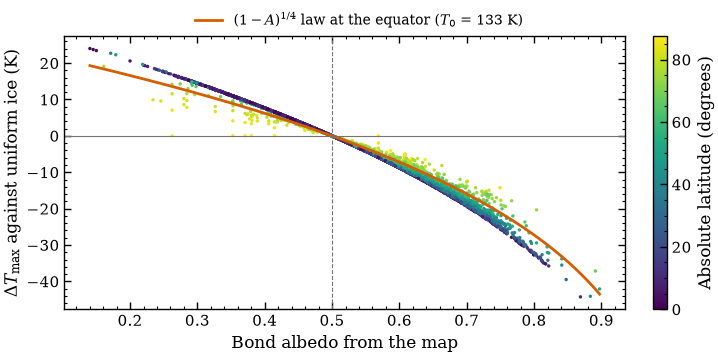

In [15]:
A0 = 0.5
residual = tmax_map - tmax * ((1.0 - albedo) / (1.0 - A0)) ** 0.25
equator = np.abs(lat) < 10.0
T0 = float(np.median(tmax[equator]))
a_curve = np.linspace(albedo.min(), albedo.max(), 200)

fig, ax = plt.subplots(figsize=(plots.DOUBLE_W, 3.6), layout="constrained")
art = ax.scatter(albedo, d_tmax, c=np.abs(lat), cmap=plots.CMAP_SCALAR, s=6, linewidths=0)
ax.plot(a_curve, T0 * (((1.0 - a_curve) / (1.0 - A0)) ** 0.25 - 1.0),
        color=plots.VERMILLION, label=rf"$(1-A)^{{1/4}}$ law at the equator ($T_0$ = {T0:.0f} K)")
ax.axhline(0.0, color="0.45", lw=0.8)
ax.axvline(A0, color="0.45", lw=0.8, ls="--")
ax.set_xlabel("Bond albedo from the map")
ax.set_ylabel(r"$\Delta T_\mathrm{max}$ against uniform ice (K)")
fig.legend(loc="outside upper center")
plots.colorbar(fig, art, ax, "Absolute latitude (degrees)")
print(f"law against run: mean residual {residual.mean():+.2f} K, "
      f"RMS {residual.std():.2f} K, worst face {np.abs(residual).max():.1f} K")

The change has the expected sign and size. Darker faces absorb more and become warmer, brighter
faces become colder, and the division falls at the 0.5 of the uniform run. The correlation between
albedo and temperature change is close to $-1$, as it must be, because at this resolution, without
radiation exchange or topography, albedo is the only difference between one equatorial face and
another.

The change is large. The map ranges from 0.14 to 0.90 in Bond albedo, and the maximum temperatures
change by tens of kelvin, more than the eclipse does. A temperature for Europa's surface has to be
quoted with the albedo that produced it.

The night side changes less. The change in $T_\mathrm{min}$ is about half the change in
$T_\mathrm{max}$, because the night temperature is set by heat stored during the day and released
slowly, which damps the response to any change in absorbed flux.

The equilibrium law is close but not exact. The curve for the equator follows the dark points
with a residual of a couple of kelvin RMS. The points above the curve are faces at high latitude,
shown in pale colors. Each face has its own starting temperature for uniform ice, so faces away
from the equator follow shallower versions of the same law.

The comparison has limits. The map is a Bond albedo in the solar band only. Emissivity stays at
0.9 and the thermal properties are uniform, so this is not a model of compositional units. At
level 4 a face is about 250 km across, which resolves the contrast between hemispheres but not
individual chaos regions. `Europa_Albedo_res6.bin` and finer maps are in the same dataset.

## 9. Albedo sweeps with an albedo map

Albedo is the property to vary on Europa, since section 8 showed it changing the maximum
temperature by tens of kelvin. A single value is set with `thermophysical.albedo_override` or
the `--albedo` option, which do the same thing. `emissivity_override`, `ks_override` and
`kd_override` work the same way on any built-in body, and notebook 01, section 10 lists all of
them with the two definitions of thermal inertia.

The question here is what that value does when a map is also loaded. `illumination.use_albedo_map`
is true unless a configuration sets it, so a configuration that does not mention it loads the map.
The two sweeps below differ only in that key.

In [16]:
from ptm import Sweep

GRID = {"albedo": [0.3, 0.5, 0.7]}
uniform = Sweep(pre.root / CONFIG, grid=GRID,
                outdir=pre.root / "output/europa_albedo_uniform")
with_map = Sweep(pre.root / "examples/quickstart_europa_albedo_map.yaml", grid=GRID,
                 outdir=pre.root / "output/europa_albedo_mapped")
uniform.run()
with_map.run()

[sweep] engine <repo>/build/bin/ptm_thermal_sim (md5 8caa975e42ef186ade0505dbc131f15f)
[sweep] axis albedo: 3 values -> --albedo (engine advertises it)


[sweep] ok   albedo-0p3 (11.8 s)


[sweep] ok   albedo-0p5 (11.6 s)


[sweep] ok   albedo-0p7 (11.3 s)
[sweep] 3 complete, 0 failed, 0 skipped, 34.7 s
[sweep] engine <repo>/build/bin/ptm_thermal_sim (md5 8caa975e42ef186ade0505dbc131f15f)
[sweep] axis albedo: 3 values -> --albedo (engine advertises it)
[sweep]   note (albedo): illumination.use_albedo_map is in force, and a loaded per-face albedo map out-ranks the scalar albedo: the sweep axis would only move the equilibration seed and uncovered faces. Set illumination.use_albedo_map: false to sweep albedo directly.


[sweep] ok   albedo-0p3 (11.3 s)


[sweep] ok   albedo-0p5 (11.6 s)


[sweep] ok   albedo-0p7 (11.7 s)
[sweep] 3 complete, 0 failed, 0 skipped, 34.6 s


{'planned': 3,
 'skipped': 0,
 'complete': 3,
 'failed': 0,
 'not_attempted': 0,
 'wall_seconds': 34.6,
 'dry_run': False}

Before running, `Sweep` checked the base configuration and, for the run with the map only, noted
that the map takes precedence over the single value. The model's log gives the same note. A
sweep run without reading them would finish and produce a figure that shows no effect.

use_albedo_map: false: equatorial median Tmax 113.71-147.50 K (span 33.79 K), 3 distinct checksums
use_albedo_map: true: equatorial median Tmax 133.57-133.57 K (span 0.00 K), 1 distinct checksums
the map's own albedo over that band: mean 0.500
WARNING WARNING: thermophysical.albedo_override = 0.3 is set AND a per-face albedo map is configured.


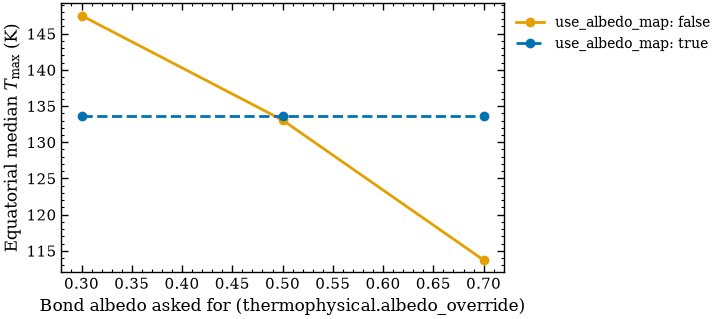

In [17]:
import hashlib

eq = np.abs(lat) < 10.0
fig, ax = plt.subplots(figsize=(plots.DOUBLE_W, 3.2), layout="constrained")
for sweep, style, label in ((uniform, dict(color=plots.ORANGE, ls="-"), "use_albedo_map: false"),
                            (with_map, dict(color=plots.BLUE, ls="--"), "use_albedo_map: true")):
    y = sweep.collect(lambda r: float(np.median(r.stat("temperature", "max")[eq])))
    seen = {hashlib.md5((pt.dir / "statistics" / "temperature_max.bin").read_bytes()
                        ).hexdigest() for pt in sweep.points}
    ax.plot(sweep.values("albedo"), y, marker="o", **style, label=label)
    print(f"{label}: equatorial median Tmax {y.min():.2f}-{y.max():.2f} K "
          f"(span {y.max() - y.min():.2f} K), {len(seen)} distinct checksums")
print(f"the map's own albedo over that band: mean {albedo[eq].mean():.3f}")
print(next(l for l in (with_map.points[0].dir / "engine.log").read_text().splitlines()
           if "albedo map is configured" in l))
ax.set_xlabel("Bond albedo asked for (thermophysical.albedo_override)")
ax.set_ylabel(r"Equatorial median $T_\mathrm{max}$ (K)")
ax.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0));

The map takes precedence. Changing the requested albedo from 0.3 to 0.7 changes the median
maximum temperature at the equator by 33.8 K without the map, and not at all with it. The three
runs with the map give identical files, with one checksum. The absorbed flux uses the map, and the
single value applies only to faces the map does not cover, of which there are none here.

The checksum test finds this. One distinct checksum across three values of a swept parameter means
the parameter had no effect. When the checksums do differ, look at the size of the change before
concluding that it is the intended one.

The two lines cross near 0.5 by coincidence. They meet where the single value equals the map's own
mean over the equatorial faces, printed above. The single value does not take effect there.

To sweep albedo, set `illumination.use_albedo_map: false`, so the single value applies. That is
the orange line, and it is what notebook 01, section 10 does on the Moon. To keep the map and
change the albedo, change the map. `illumination.albedo_map` names a file, and the file read
in section 8 holds a count followed by one 8-byte float per face, so a scaled copy takes a few lines
of NumPy with `ptm.readers.read_albedo_map`.

Both sweeps keep emissivity, thermal inertia and internal heat flow at Europa's built-in values, so
they give no information about those properties. The same question of precedence applies to the
H-parameter and thermal-inertia maps, which neither run loads.

## 10. Exercises

1. A window without an eclipse. The eclipse comes from the SPICE geometry, and every window of one
   full orbit contains one. For comparison, use `start_time: '2025-01-02T00:00:00'` with
   `duration_days: 1.5` and `timesteps: 81`, which falls between this eclipse and the next, and
   compare the uninterrupted peak with the peak after the eclipse in this run.

2. Set `include_primary_reflection: false` and run again. In the final summary of the log,
   `Primary reflected` drops to nearly zero while `Primary IR` is almost unchanged, as described in
   section 3.

3. Resolution. Raise `mesh.resolution` to 5 (20,480 faces, with `Europa_Albedo_res5.bin` from the
   same dataset) and repeat the pair of section 8. The contrast between hemispheres should barely
   change, while the spread of changes from face to face grows, because a finer mesh resolves
   patches that level 4 averages together. `scripts/ptm_mem_estimate.py --faces 20480 --steps 192`
   estimates the memory first.

4. Albedo over the observed range. The uniform runs of section 9 span 0.3 to 0.7, and Europa's map
   spans 0.14 to 0.90. Run the uniform case at the two ends of the map's range, and compare the
   spread of maximum temperatures with the change from face to face that the map itself produces,
   -44.3 to +24.0 K in section 8.